In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.model_selection import (
    train_test_split, GridSearchCV, GroupKFold, StratifiedKFold, cross_val_score
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv(r'C:/Users/hibah/rd/Final_SDM_Data.csv')
BOUNDARY_PATH = gpd.read_file(r"rd/INDIAN_PINCODE_BOUNDARY.geojson")

In [3]:
COORDS = ['decimalLongitude', 'decimalLatitude']
NON_PREDICTORS = ['presence', 'koppen_zone'] + COORDS 
predictor_cols = [col for col in df.columns if col not in NON_PREDICTORS]

X = df[predictor_cols]
y = df['presence']

# 2. Define the VIF calculation function
def calculate_vif(data):
    Xc = add_constant(data)  # VIF needs a constant column
    return pd.DataFrame({
        'Feature': data.columns,
        'VIF': [variance_inflation_factor(Xc.values, i + 1)
                for i in range(data.shape[1])],
    })

# 3. Iteratively drop features with VIF >= 5
X_vif = df[predictor_cols].copy()
while X_vif.shape[1] > 1:
    vif = calculate_vif(X_vif)
    max_vif = vif['VIF'].max()
    if max_vif < 5:
        break
    drop = vif.loc[vif['VIF'].idxmax(), 'Feature']
    print(f'Removing {drop}: VIF={max_vif:.2f}')
    X_vif = X_vif.drop(columns=[drop])
 
final_predictors = X_vif.columns.tolist()
print(f'\n{len(final_predictors)} predictors kept:\n{final_predictors}')
print(calculate_vif(X_vif).round(2))


C:\Users\hibah\AppData\Local\Temp\ipykernel_34712\3880136798.py:13: UserWarning: The design matrix is poorly conditioned (condition number=3.12e+07). VIF calculations may be numerically unstable.
  'VIF': [variance_inflation_factor(Xc.values, i + 1)


Removing bio7_temperature_annual_range: VIF=69286148113392.25
Removing bio11_mean_temp_coldest_quarter: VIF=1285.76
Removing bio10_mean_temp_warmest_quarter: VIF=324.98
Removing bio6_min_temp_coldest_month: VIF=294.67
Removing bio16_precipitation_wettest_quarter: VIF=247.90
Removing bio12_annual_precipitation: VIF=47.70
Removing bio5_max_temp_warmest_month: VIF=39.49
Removing bio4_temperature_seasonality: VIF=28.18
Removing bio17_precipitation_driest_quarter: VIF=10.34
Removing bio15_precipitation_seasonality: VIF=7.00
Removing bio1_annual_mean_temperature: VIF=6.15

13 predictors kept:
['dist_in_km_railways', 'dist_in_km_road', 'distance_in_km_urban', 'distance_in_km_lakes', 'dist_in_km_river', 'bio13_precipitation_wettest_month', 'bio14_precipitation_driest_month', 'bio18_precipitation_warmest_quarter', 'bio19_precipitation_coldest_quarter', 'bio2_mean_diurnal_range', 'bio3_isothermality', 'bio8_mean_temp_wettest_quarter', 'bio9_mean_temp_driest_quarter']
                            

In [4]:
#split data

In [5]:
X = df[final_predictors]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
coords_test = df.loc[X_test.index, COORDS]

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_params = {
    'n_estimators': [100, 200, 500],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

rf_grid.fit(X_train_scaled, y_train)

rf_best = rf_grid.best_estimator_

print(rf_grid.best_params_)
print('Best CV AUC:', round(rf_grid.best_score_, 4))
 
# %% 6. Prediction + metrics on the test set
y_pred = rf_best.predict(X_test_scaled)
y_prob = rf_best.predict_proba(X_test_scaled)[:, 1]

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 500}
Best CV AUC: 0.9106


In [8]:
results = pd.Series({
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    'ROC_AUC': roc_auc_score(y_test, y_prob),
}).round(4)
print(results)

Accuracy     0.8321
Precision    0.8376
Recall       0.8239
F1           0.8307
ROC_AUC      0.9057
dtype: float64


Random CV AUC : 0.915 +/- 0.006
Spatial CV AUC: 0.819 +/- 0.024


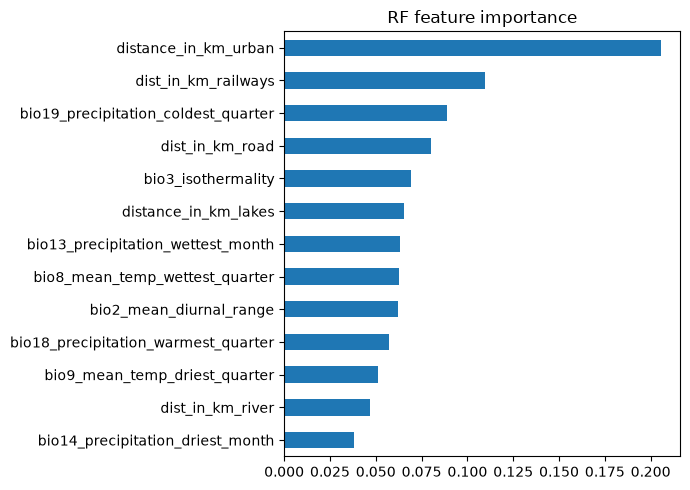

In [9]:
BLOCK_DEG = 2.0
blocks = (
    (df['decimalLongitude'] // BLOCK_DEG).astype(int).astype(str) + '_' +
    (df['decimalLatitude'] // BLOCK_DEG).astype(int).astype(str)
)
groups = pd.factorize(blocks)[0]
 
rf_cv = RandomForestClassifier(**rf_grid.best_params_, random_state=42, n_jobs=-1)
auc_random = cross_val_score(
    rf_cv, X, y, scoring='roc_auc',
    cv=StratifiedKFold(5, shuffle=True, random_state=42))
auc_spatial = cross_val_score(
    rf_cv, X, y, scoring='roc_auc', cv=GroupKFold(5), groups=groups)
print(f'Random CV AUC : {auc_random.mean():.3f} +/- {auc_random.std():.3f}')
print(f'Spatial CV AUC: {auc_spatial.mean():.3f} +/- {auc_spatial.std():.3f}')
# A big drop for spatial CV means the random-split score is optimistic.
 
# %% 8. Feature importance
imp = pd.Series(rf_best.feature_importances_, index=final_predictors).sort_values()
imp.plot.barh(figsize=(7, 5), title='RF feature importance')
plt.tight_layout()
plt.show()

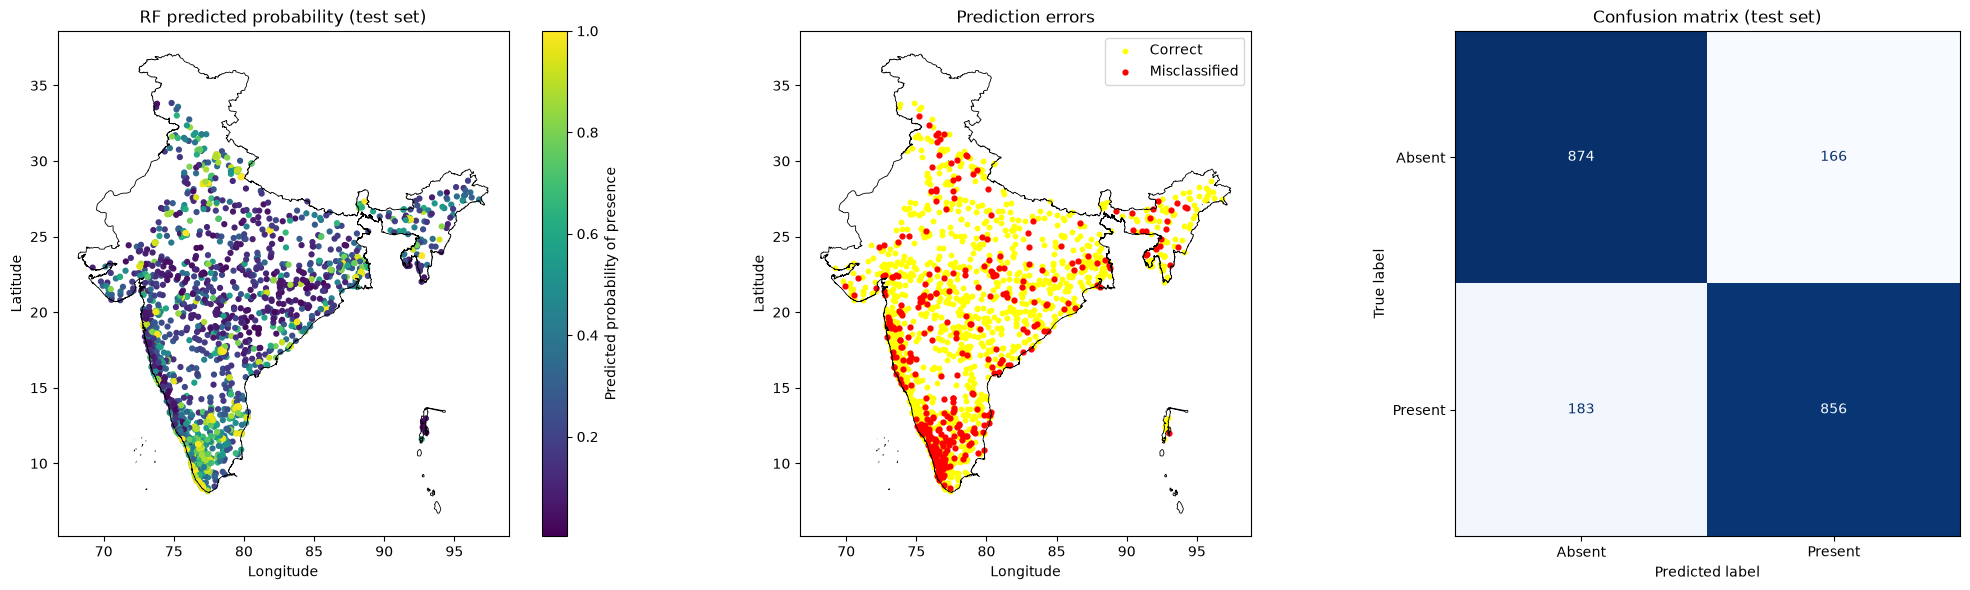

In [10]:
import geopandas as gpd

def load_boundary(src):
    if src is None:
        return None
    gdf = gpd.read_file(src) if isinstance(src, (str, bytes)) else src.copy()
    if gdf.crs is not None:
        gdf = gdf.to_crs(epsg=4326)
    gdf['geometry'] = gdf.geometry.make_valid()
    return gdf.dissolve()

BOUNDARY = load_boundary(BOUNDARY_PATH)   # works with a path or BOUNDARY_GDF
 
def add_boundary(ax):
    if BOUNDARY is not None:
        BOUNDARY.boundary.plot(ax=ax, color='k', linewidth=0.6)
 
out = coords_test.copy()
out['actual'] = y_test.values
out['prob'] = y_prob
out['pred'] = y_pred
correct = out['actual'] == out['pred']
 
fig, ax = plt.subplots(1, 3, figsize=(21, 6),
                       gridspec_kw={'width_ratios': [1, 1, 0.9]})
ax[1].sharex(ax[0])
ax[1].sharey(ax[0])
 
sc = ax[0].scatter(out['decimalLongitude'], out['decimalLatitude'],
                   c=out['prob'], cmap='viridis', s=12)
plt.colorbar(sc, ax=ax[0], label='Predicted probability of presence')
ax[0].set_title('RF predicted probability (test set)')
 
ax[1].scatter(out.loc[correct, 'decimalLongitude'],
              out.loc[correct, 'decimalLatitude'],
              c='yellow', s=10, label='Correct')
ax[1].scatter(out.loc[~correct, 'decimalLongitude'],
              out.loc[~correct, 'decimalLatitude'],
              c='red', s=12, label='Misclassified')
ax[1].legend()
ax[1].set_title('Prediction errors')
 
for a in ax[:2]:
    add_boundary(a)
    a.set_xlabel('Longitude')
    a.set_ylabel('Latitude')
 
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Absent', 'Present'],
    cmap='Blues', values_format='d', ax=ax[2], colorbar=False
)
ax[2].set_title('Confusion matrix (test set)')
 
plt.tight_layout()
plt.show()
 


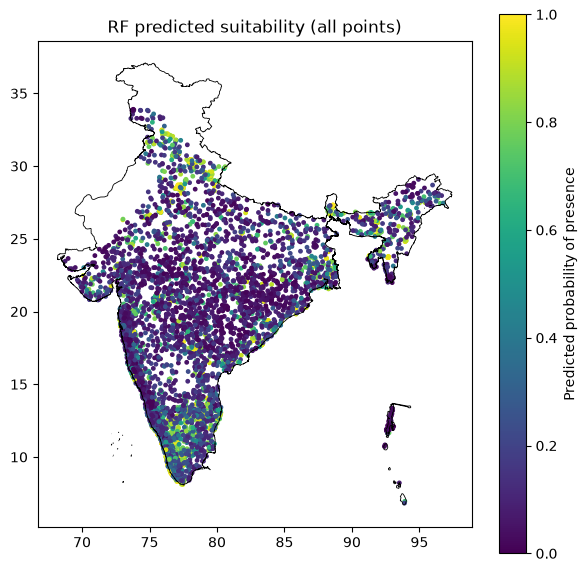

In [11]:
all_prob = rf_best.predict_proba(scaler.transform(df[final_predictors]))[:, 1]

fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(df['decimalLongitude'], df['decimalLatitude'],
                c=all_prob, cmap='viridis', s=6)
plt.colorbar(sc, label='Predicted probability of presence')
add_boundary(ax)
ax.set_title('RF predicted suitability (all points)')
plt.show()

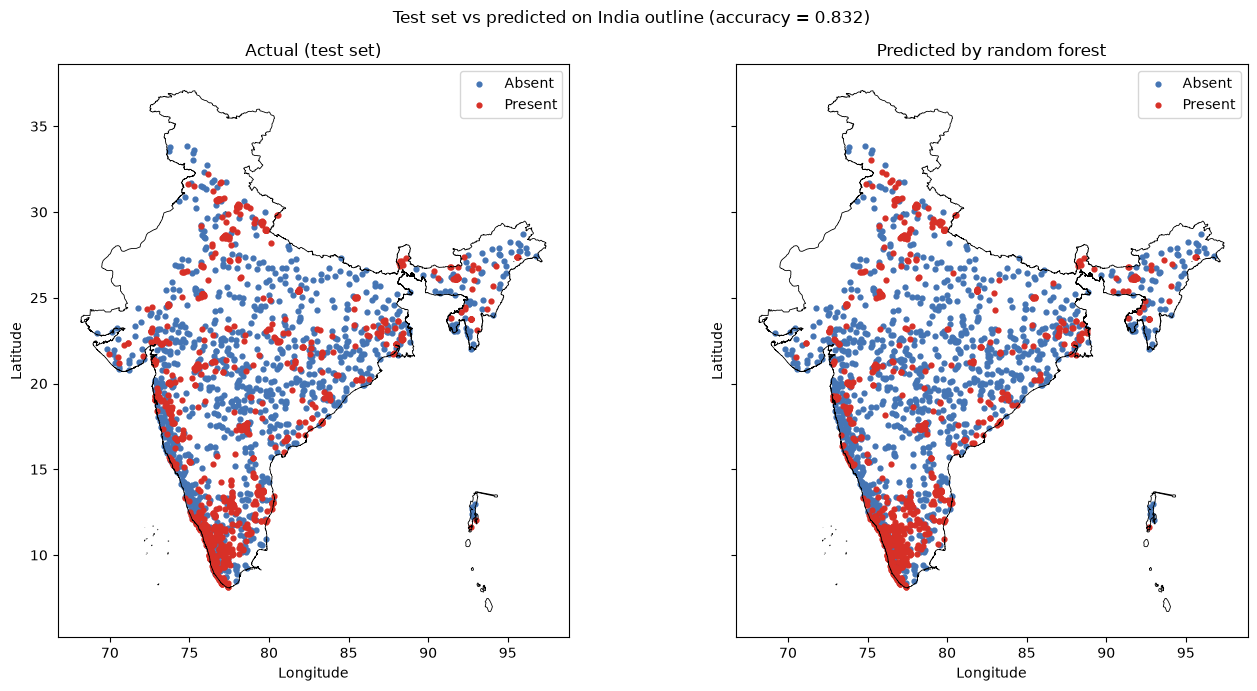

In [12]:
import matplotlib.pyplot as plt
 
colors = {0: '#4575b4', 1: '#d73027'}     # absent = blue, present = red
names = {0: 'Absent', 1: 'Present'}
 
fig, ax = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
for a, col, title in [(ax[0], 'actual', 'Actual (test set)'),
                      (ax[1], 'pred', 'Predicted by random forest')]:
    for k in (0, 1):
        m = out[col] == k
        a.scatter(out.loc[m, 'decimalLongitude'], out.loc[m, 'decimalLatitude'],
                  c=colors[k], s=12, label=names[k])
    add_boundary(a)
    a.set_title(title)
    a.set_xlabel('Longitude')
    a.set_ylabel('Latitude')
    a.legend(loc='upper right')
 
acc = (out['actual'] == out['pred']).mean()
fig.suptitle(f'Test set vs predicted on India outline (accuracy = {acc:.3f})')
plt.tight_layout()
plt.show()

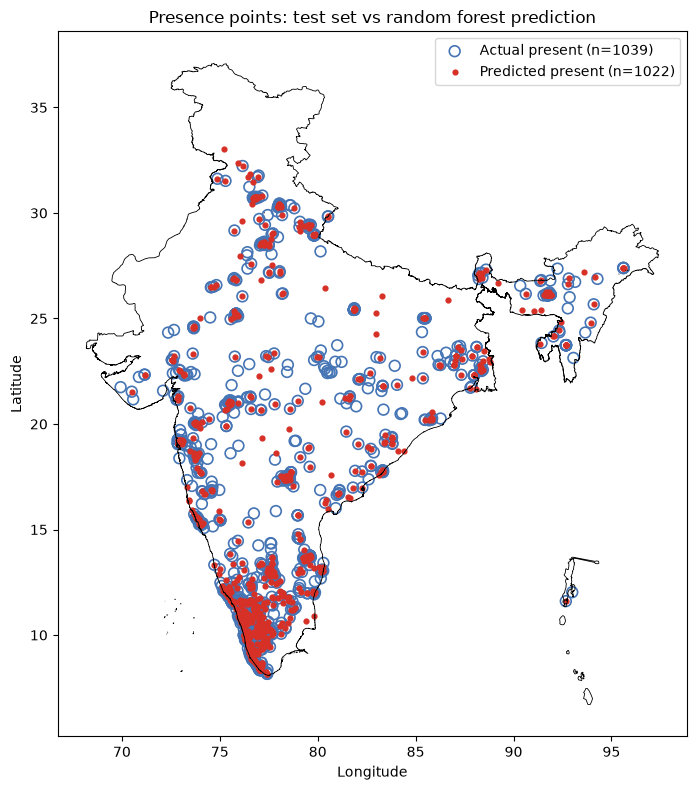

In [13]:
# Run after your notebook has `out` (test-set coordinates with 'actual' and 'pred')
# and add_boundary(ax) defined -- both exist in your current notebook.
import matplotlib.pyplot as plt

actual_present = out[out['actual'] == 1]
pred_present = out[out['pred'] == 1]

fig, ax = plt.subplots(figsize=(8, 8))

# Test set (actual presence): hollow blue rings
ax.scatter(actual_present['decimalLongitude'], actual_present['decimalLatitude'],
           s=60, facecolors='none', edgecolors='#4575b4', linewidths=1.2,
           label=f'Actual present (n={len(actual_present)})')

# Model prediction (predicted presence): small red dots
ax.scatter(pred_present['decimalLongitude'], pred_present['decimalLatitude'],
           s=12, c='#d73027', label=f'Predicted present (n={len(pred_present)})')

add_boundary(ax)
ax.set_title('Presence points: test set vs random forest prediction')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()